### **NAMA : FIRZANI NUR**
### **NIM : H061241026**
### **KELAS : C**
### **MATA KULIAH : KECERDASAN ARTIFISIAL**
---

# **Membuat Recipe Menggunakan Data Katalog Gempa USGS/BMKG di Wilayah Sulawesi**

## 1. Instalasi dan import library

In [1]:
import os
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)

## 2. Parameter

In [2]:
# Bounding box Sulawesi dan sekitarnya
MIN_LAT, MAX_LAT = -6.5, 2.0
MIN_LON, MAX_LON = 118.5, 126.5

START_DATE = "2010-01-01"
END_DATE = date.today().isoformat()
MIN_MAG = 4.0          # API USGS membatasi maksimal 20.000 data per permintaan

K_RANGE = range(2, 11) # rentang k untuk K-Means
DBSCAN_EPS_KM = 50     # radius tetangga DBSCAN (km)
DBSCAN_MIN_SAMPLES = 15

## 3. Unduh data dari USGS

In [4]:
import io, time, requests

BASE_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"

def unduh_usgs(start, end, retries=4):
    params = {
        "format": "csv", "starttime": start, "endtime": end,
        "minlatitude": MIN_LAT, "maxlatitude": MAX_LAT,
        "minlongitude": MIN_LON, "maxlongitude": MAX_LON,
        "minmagnitude": MIN_MAG, "orderby": "time",
    }
    for i in range(retries):
        try:
            r = requests.get(BASE_URL, params=params, timeout=120,
                             headers={"User-Agent": "Mozilla/5.0"})
            if r.status_code == 200:
                return pd.read_csv(io.StringIO(r.text))
            if r.status_code == 204:          # tidak ada data pada periode itu
                return pd.DataFrame()
            print(f"  {start}: HTTP {r.status_code}, coba lagi ({i+1}/{retries})")
        except requests.RequestException as e:
            print(f"  {start}: {type(e).__name__}, coba lagi ({i+1}/{retries})")
        time.sleep(5 * (i + 1))
    return None

bagian, gagal = [], []
for yr in range(int(START_DATE[:4]), int(END_DATE[:4]) + 1):
    s = max(START_DATE, f"{yr}-01-01")
    e = min(END_DATE, f"{yr}-12-31")
    hasil = unduh_usgs(s, e)
    if hasil is None:
        gagal.append(yr)
    elif len(hasil) > 0:
        bagian.append(hasil)
    print(f"{yr}: {0 if hasil is None else len(hasil)} data")

if gagal:
    print("Tahun yang gagal diunduh:", gagal, "-> jalankan ulang sel ini")

df_raw = pd.concat(bagian, ignore_index=True).drop_duplicates(subset="id")
df_raw.to_csv("data/katalog_usgs_sulawesi_raw.csv", index=False)
print("Jumlah data mentah:", len(df_raw))
df_raw.head()

2010: 147 data
2011: 159 data
2012: 161 data
2013: 157 data
2014: 369 data
2015: 258 data
2016: 232 data
2017: 217 data
2018: 348 data
2019: 436 data
2020: 223 data
2021: 314 data
2022: 224 data
2023: 235 data
2024: 206 data
2025: 238 data
2026: 468 data
Jumlah data mentah: 4392


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2010-12-26T04:00:10.160Z,-3.492,123.353,24.8,4.3,mb,18.0,75.7,NaN,0.85,...,2014-11-07T01:43:14.957Z,"107 km ENE of Kendari, Indonesia",earthquake,NaN,17.6,NaN,3.0,reviewed,us,us
1,2010-12-24T01:19:40.110Z,-0.209,122.882,95.7,4.2,mb,15.0,162.3,NaN,0.69,...,2014-11-07T01:43:13.484Z,"82 km N of Luwuk, Indonesia",earthquake,NaN,11.3,NaN,5.0,reviewed,us,us
2,2010-12-22T13:19:33.400Z,-0.737,121.917,10.0,4.8,mb,28.0,68.9,NaN,0.90,...,2014-11-07T01:43:12.371Z,"99 km WNW of Luwuk, Indonesia",earthquake,NaN,NaN,NaN,7.0,reviewed,us,us
3,2010-12-21T04:21:29.530Z,0.161,122.244,187.9,4.9,mb,95.0,24.9,NaN,1.15,...,2014-11-07T01:43:10.338Z,"100 km WSW of Gorontalo, Indonesia",earthquake,NaN,5.4,NaN,35.0,reviewed,us,us
4,2010-12-20T20:11:20.220Z,-1.788,120.249,49.8,4.3,mb,13.0,126.0,NaN,1.25,...,2014-11-07T01:43:10.228Z,"70 km SW of Poso, Indonesia",earthquake,NaN,17.7,NaN,3.0,reviewed,us,us


## 4. Pembersihan data

In [5]:
kolom = ["time", "latitude", "longitude", "depth", "mag", "magType", "place"]
df = df_raw[kolom].copy()

df["time"] = pd.to_datetime(df["time"])
df = df.dropna(subset=["latitude", "longitude", "depth", "mag"])
df = df[df["depth"] >= 0]                       # kedalaman negatif dianggap tidak valid
df = df.drop_duplicates(subset=["time", "latitude", "longitude"])
df = df.reset_index(drop=True)

df.to_csv("data/katalog_usgs_sulawesi_clean.csv", index=False)
print("Jumlah data bersih:", len(df))
df.describe()

Jumlah data bersih: 4392


,latitude,longitude,depth,mag
count,4392.000000,4392.000000,4392.000000,4392.000000
mean,-0.097275,124.082654,75.606232,4.530806
std,1.715684,2.235547,96.966240,0.402141
min,-6.493000,118.521000,3.360000,4.000000
25%,-0.579250,122.391600,24.795000,4.300000
50%,0.300700,124.586000,40.795000,4.400000
75%,1.108125,126.215925,82.000000,4.700000
max,2.000000,126.499700,652.530000,7.500000


## 5. Eksplorasi data

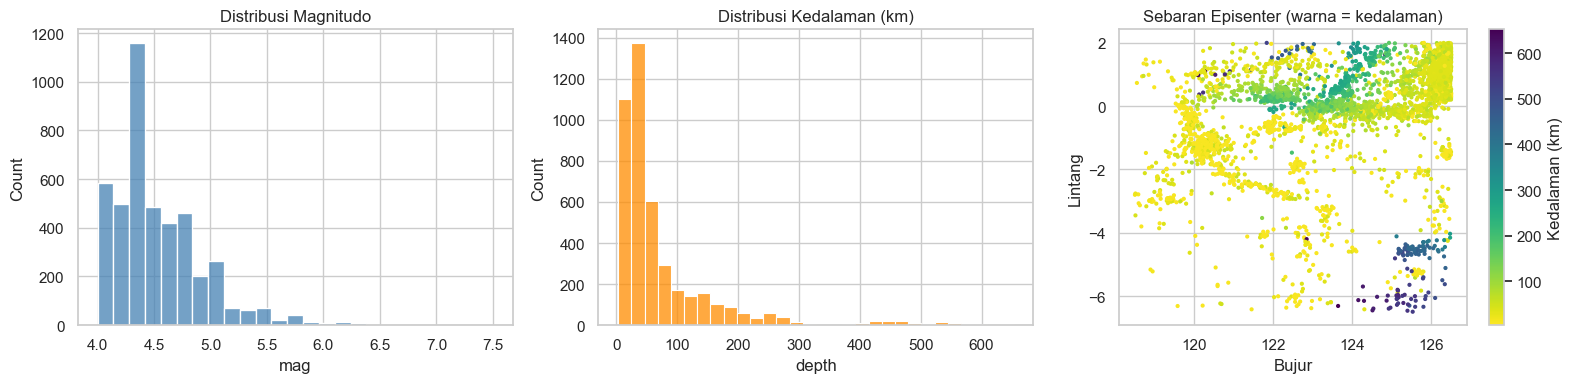

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["mag"], bins=25, ax=ax[0], color="steelblue")
ax[0].set_title("Distribusi Magnitudo")
sns.histplot(df["depth"], bins=30, ax=ax[1], color="darkorange")
ax[1].set_title("Distribusi Kedalaman (km)")
sc = ax[2].scatter(df["longitude"], df["latitude"], c=df["depth"], s=4, cmap="viridis_r")
ax[2].set_title("Sebaran Episenter (warna = kedalaman)")
ax[2].set_xlabel("Bujur"); ax[2].set_ylabel("Lintang")
plt.colorbar(sc, ax=ax[2], label="Kedalaman (km)")
plt.tight_layout()
plt.show()

## 6. Feature engineering
Koordinat lintang/bujur diubah ke satuan kilometer agar jarak horizontal setara dengan kedalaman, lalu semua fitur distandardisasi.
Kategori kedalaman (dangkal/menengah/dalam) dibuat untuk tugas supervised di bagian 9.

In [7]:
lat0, lon0 = df["latitude"].mean(), df["longitude"].mean()
df["x_km"] = (df["longitude"] - lon0) * 111.32 * np.cos(np.radians(lat0))
df["y_km"] = (df["latitude"] - lat0) * 110.57

fitur = ["x_km", "y_km", "depth"]
X = StandardScaler().fit_transform(df[fitur])

def kategori_kedalaman(d):
    if d < 70:
        return "Dangkal (<70 km)"
    elif d < 300:
        return "Menengah (70-300 km)"
    return "Dalam (>300 km)"

df["kategori_depth"] = df["depth"].apply(kategori_kedalaman)
df["kategori_depth"].value_counts()

kategori_depth
Dangkal (<70 km)        3121
Menengah (70-300 km)    1117
Dalam (>300 km)          154
Name: count, dtype: int64

## 7. K-Means: memilih jumlah klaster

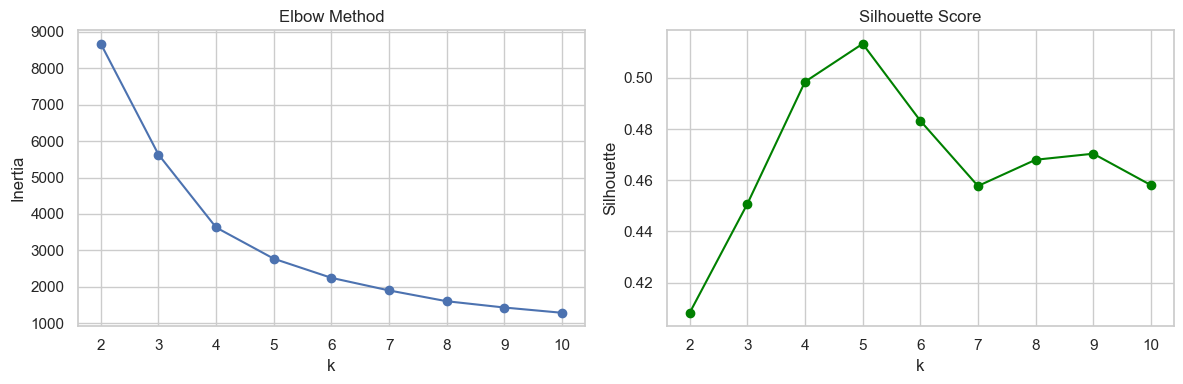

k terbaik berdasarkan silhouette: 5


In [8]:
inertia, sil = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=min(5000, len(X)), random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(K_RANGE), inertia, "o-")
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(K_RANGE), sil, "o-", color="green")
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

BEST_K = list(K_RANGE)[int(np.argmax(sil))]
print("k terbaik berdasarkan silhouette:", BEST_K)

In [9]:
# Anda boleh menimpa BEST_K secara manual berdasarkan hasil elbow dan interpretasi geologi, mis. BEST_K = 6
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE).fit(X)
df["cluster_kmeans"] = kmeans.labels_

print("Silhouette K-Means:", round(silhouette_score(X, kmeans.labels_, sample_size=min(5000, len(X)), random_state=RANDOM_STATE), 3))

ringkasan_km = df.groupby("cluster_kmeans").agg(
    jumlah=("mag", "size"),
    mag_rata2=("mag", "mean"),
    mag_maks=("mag", "max"),
    depth_rata2=("depth", "mean"),
    lat_pusat=("latitude", "mean"),
    lon_pusat=("longitude", "mean"),
).round(2)
ringkasan_km

Silhouette K-Means: 0.513


,jumlah,mag_rata2,mag_maks,depth_rata2,lat_pusat,lon_pusat
cluster_kmeans,,,,,,
0,2101,4.55,7.4,41.19,0.81,125.93
1,1024,4.48,6.3,154.04,0.43,123.13
2,126,4.44,6.3,489.48,-4.64,125.16
3,283,4.51,6.2,21.21,-3.90,123.52
4,858,4.57,7.5,23.44,-1.03,120.71


## 8. DBSCAN
DBSCAN mengelompokkan berdasarkan kepadatan titik dan menandai titik terisolasi sebagai noise (label -1). Di sini dipakai jarak haversine pada koordinat episenter (2D) sehingga eps dinyatakan dalam km.

In [10]:
coords_rad = np.radians(df[["latitude", "longitude"]].values)
eps_rad = DBSCAN_EPS_KM / 6371.0088

db = DBSCAN(eps=eps_rad, min_samples=DBSCAN_MIN_SAMPLES, metric="haversine", algorithm="ball_tree").fit(coords_rad)
df["cluster_dbscan"] = db.labels_

n_klaster = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = int((db.labels_ == -1).sum())
print(f"Jumlah klaster DBSCAN: {n_klaster}")
print(f"Jumlah noise: {n_noise} ({n_noise / len(df):.1%})")

mask = db.labels_ != -1
if n_klaster > 1:
    print("Silhouette DBSCAN (tanpa noise):", round(silhouette_score(X[mask], db.labels_[mask], sample_size=min(5000, int(mask.sum())), random_state=RANDOM_STATE), 3))

df[df["cluster_dbscan"] != -1].groupby("cluster_dbscan").agg(
    jumlah=("mag", "size"),
    mag_rata2=("mag", "mean"),
    depth_rata2=("depth", "mean"),
    lat_pusat=("latitude", "mean"),
    lon_pusat=("longitude", "mean"),
).round(2)

Jumlah klaster DBSCAN: 5
Jumlah noise: 104 (2.4%)
Silhouette DBSCAN (tanpa noise): 0.059


,jumlah,mag_rata2,depth_rata2,lat_pusat,lon_pusat
cluster_dbscan,,,,,
0,4041,4.54,67.09,0.24,124.04
1,19,4.43,26.53,-2.20,125.75
2,45,4.46,20.37,-1.45,126.35
3,160,4.48,324.38,-4.78,125.65
4,23,4.53,15.20,-6.05,122.56


## 9. Pembanding supervised: Random Forest
Model memprediksi **kategori kedalaman** dari posisi dan magnitudo. Hasilnya menunjukkan seberapa kuat pola spasial kedalaman gempa (zona subduksi) bisa dipelajari mesin.

Akurasi: 0.906
                      precision    recall  f1-score   support

     Dalam (>300 km)       0.85      0.74      0.79        31
    Dangkal (<70 km)       0.94      0.93      0.94       625
Menengah (70-300 km)       0.82      0.85      0.84       223

            accuracy                           0.91       879
           macro avg       0.87      0.84      0.85       879
        weighted avg       0.91      0.91      0.91       879



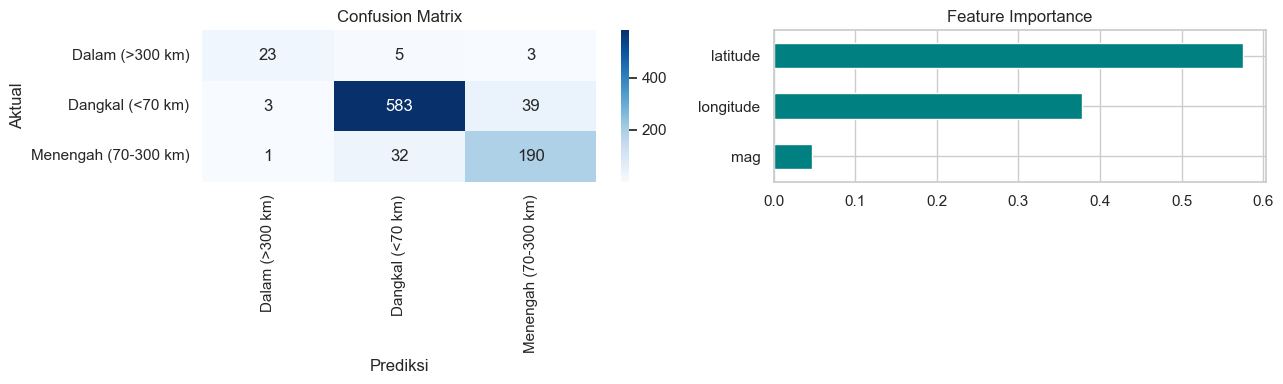

In [11]:
fitur_rf = ["latitude", "longitude", "mag"]
X_tr, X_te, y_tr, y_te = train_test_split(
    df[fitur_rf], df["kategori_depth"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["kategori_depth"]
)

rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)
rf.fit(X_tr, y_tr)
pred = rf.predict(X_te)

print("Akurasi:", round(accuracy_score(y_te, pred), 3))
print(classification_report(y_te, pred))

labels = sorted(df["kategori_depth"].unique())
cm = confusion_matrix(y_te, pred, labels=labels)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax[0])
ax[0].set_title("Confusion Matrix"); ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual")
pd.Series(rf.feature_importances_, index=fitur_rf).sort_values().plot.barh(ax=ax[1], color="teal")
ax[1].set_title("Feature Importance")
plt.tight_layout()
plt.show()

## 10. Peta statis (Matplotlib)

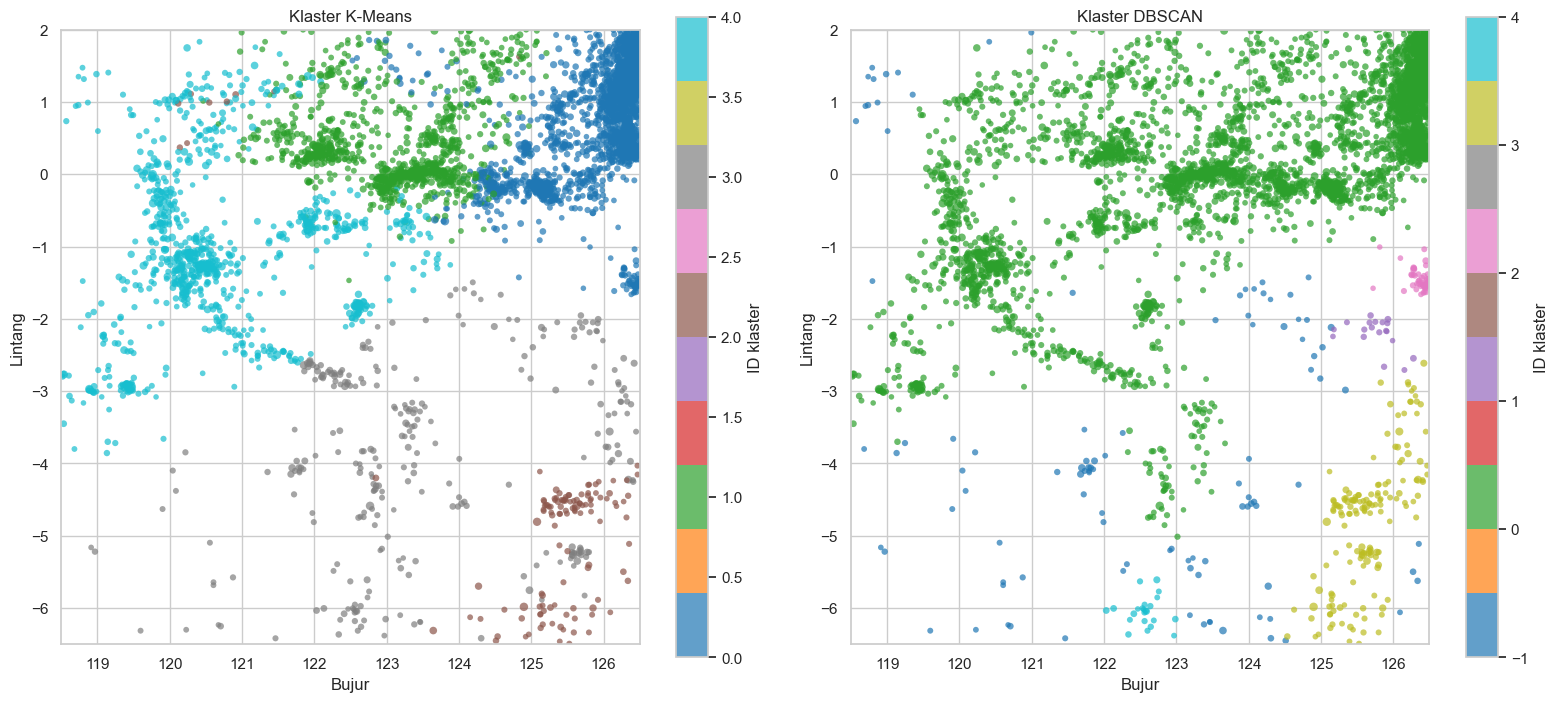

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, kolom, judul in zip(ax, ["cluster_kmeans", "cluster_dbscan"], ["K-Means", "DBSCAN"]):
    sc = a.scatter(df["longitude"], df["latitude"], c=df[kolom], s=df["mag"] ** 2, cmap="tab10", alpha=0.7, edgecolor="none")
    a.set_title(f"Klaster {judul}")
    a.set_xlabel("Bujur"); a.set_ylabel("Lintang")
    a.set_xlim(MIN_LON, MAX_LON); a.set_ylim(MIN_LAT, MAX_LAT)
    a.set_aspect("equal")
    plt.colorbar(sc, ax=a, label="ID klaster")
plt.tight_layout()
plt.savefig("output/peta_klaster_gempa.png", dpi=200)
plt.show()

## 11. Peta interaktif (Folium)

In [13]:
palet = ["red", "blue", "green", "purple", "orange", "darkred", "cadetblue", "darkgreen",
         "pink", "lightblue", "black", "beige", "darkblue", "lightgreen"]

def warna(label):
    return "gray" if label == -1 else palet[label % len(palet)]

def buat_peta(kolom, nama):
    m = folium.Map(location=[df["latitude"].mean(), df["longitude"].mean()], zoom_start=6, tiles="OpenStreetMap")
    grup = {}
    for lab in sorted(df[kolom].unique()):
        nama_grup = "Noise" if lab == -1 else f"Klaster {lab}"
        grup[lab] = folium.FeatureGroup(name=nama_grup).add_to(m)
    for _, r in df.iterrows():
        lab = r[kolom]
        folium.CircleMarker(
            location=[r["latitude"], r["longitude"]],
            radius=max(2, (r["mag"] - 3) * 1.8),
            color=warna(lab), fill=True, fill_opacity=0.6, weight=0.5,
            popup=folium.Popup(
                f"<b>{nama}: {lab}</b><br>M {r['mag']}<br>Kedalaman: {r['depth']} km<br>{r['time']:%Y-%m-%d}<br>{r['place']}",
                max_width=250,
            ),
        ).add_to(grup[lab])
    folium.LayerControl(collapsed=False).add_to(m)
    return m

peta_km = buat_peta("cluster_kmeans", "K-Means")
peta_km.save("output/peta_kmeans.html")
peta_db = buat_peta("cluster_dbscan", "DBSCAN")
peta_db.save("output/peta_dbscan.html")
peta_km   # tampilkan peta K-Means; ganti dengan peta_db untuk DBSCAN

## 12. Simpan output

In [14]:
kolom_out = ["time", "latitude", "longitude", "depth", "mag", "place", "kategori_depth", "cluster_kmeans", "cluster_dbscan"]
df[kolom_out].to_csv("output/hasil_klaster_gempa_sulawesi.csv", index=False)
ringkasan_km.to_csv("output/ringkasan_klaster_kmeans.csv")

print("File tersimpan di folder output/:")
for f in sorted(os.listdir("output")):
    print(" -", f)

File tersimpan di folder output/:
 - hasil_klaster_gempa_sulawesi.csv
 - peta_dbscan.html
 - peta_klaster_gempa.png
 - peta_kmeans.html
 - ringkasan_klaster_kmeans.csv
